# Training Metrics Visualization

This notebook loads the latest metrics from Lightning logs and visualizes:
1. Training loss per step
2. Training and validation loss per epoch

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import glob

## Find and Load Latest Metrics CSV

In [59]:
# Find all version directories in lightning_logs
def custom_sort_key(path):
    """
    Custom sort key for log directories.
    Implement custom logic here (e.g., extract numeric version).
    Left empty per request.
    """
    return int(path.split('_')[-1])  # Example: extract version number

log_dirs = sorted(glob.glob('../lightning_logs.nosync/src.model.mae.MaskedAutoencoder__src.model.loss.DefaultMAELoss__all_60s/version_*'), key=custom_sort_key)

# Get the latest version
latest_log_dir = log_dirs[-1]
print(f"Loading metrics from: {latest_log_dir}")

# Load the metrics CSV
metrics_path = Path(latest_log_dir) / 'metrics.csv'
df = pd.read_csv(metrics_path)

print(f"\nDataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
df.head()

Loading metrics from: ../lightning_logs.nosync/src.model.mae.MaskedAutoencoder__src.model.loss.DefaultMAELoss__all_60s/version_8

Dataset shape: (71, 7)

Columns: ['epoch', 'lr-Adam', 'step', 'train_loss_epoch', 'train_loss_step', 'val_loss_epoch', 'val_loss_step']

First few rows:


,epoch,lr-Adam,step,train_loss_epoch,train_loss_step,val_loss_epoch,val_loss_step
0,NaN,0.001,0,NaN,NaN,NaN,NaN
1,0.0,NaN,9,NaN,0.707556,NaN,NaN
2,0.0,NaN,19,NaN,0.574518,NaN,NaN
3,0.0,NaN,29,NaN,0.369889,NaN,NaN
4,0.0,NaN,39,NaN,0.271578,NaN,NaN


## Plot Training Loss per Step

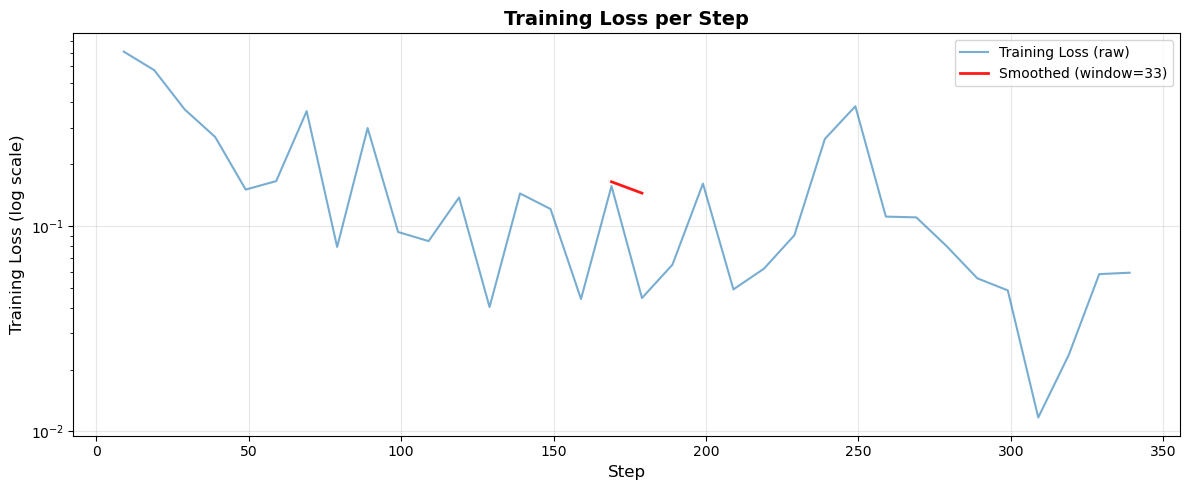

Total training steps: 34
Y-axis scale: Logarithmic
Epoch markers at: []


In [60]:
# Filter data for train_loss_step
train_loss_step = df[['step', 'train_loss_step']].dropna()

# Choose a rolling window for smoothing (odd integer, <= length)
n = len(train_loss_step)
window = 50
if window > n:
    window = n if n % 2 == 1 else n - 1
if window < 3:
    window = 3

# Compute centered rolling mean (smoothing)
smoothed = train_loss_step['train_loss_step'].rolling(window=window, center=True).mean()

# Toggle for log scale
use_log_scale = True  # Set to True for log scale y-axis

# Create the plot
plt.figure(figsize=(12, 5))
plt.plot(train_loss_step['step'], train_loss_step['train_loss_step'],
         linewidth=1.5, alpha=0.6, label='Training Loss (raw)')
# Red smoothed line on top
plt.plot(train_loss_step['step'][smoothed.notna()], smoothed.dropna(),
         color='red', linewidth=2.0, alpha=0.9, label=f'Smoothed (window={window})', zorder=10)

# Add vertical lines every 1246 steps
max_step = train_loss_step['step'].max()
epoch_step = 1246
for step_marker in range(epoch_step, int(max_step) + 1, epoch_step):
    plt.axvline(x=step_marker, color='blue', linestyle='--', linewidth=1, alpha=0.5)

plt.xlabel('Step', fontsize=12)
plt.ylabel('Training Loss', fontsize=12)
plt.title('Training Loss per Step', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

# Apply log scale if requested
if use_log_scale:
    plt.yscale('log')
    plt.ylabel('Training Loss (log scale)', fontsize=12)

plt.tight_layout()
plt.show()

print(f"Total training steps: {len(train_loss_step)}")
print(f"Y-axis scale: {'Logarithmic' if use_log_scale else 'Linear'}")
print(f"Epoch markers at: {list(range(epoch_step, int(max_step) + 1, epoch_step))}")

## Plot Training and Validation Loss per Epoch

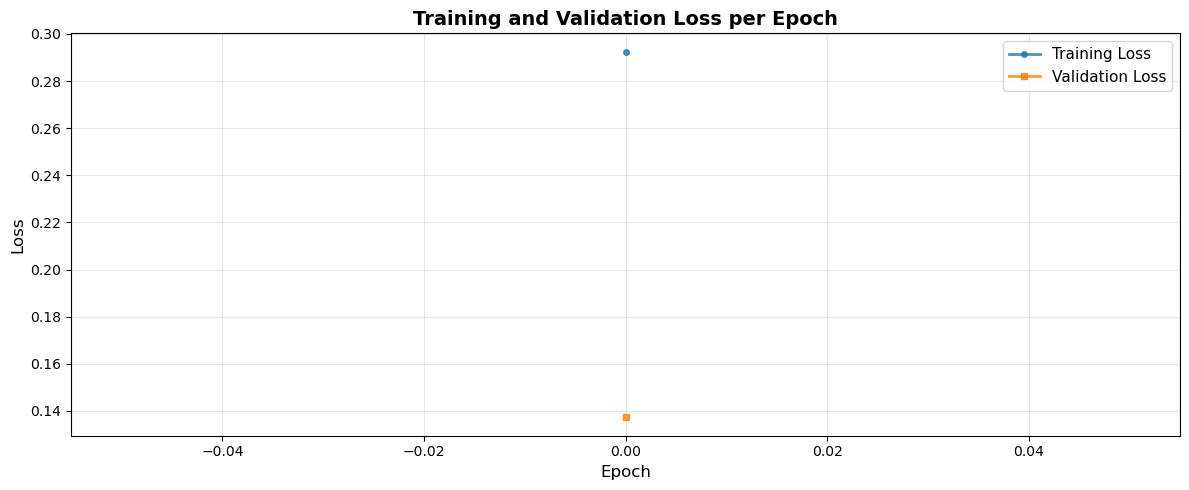

Total epochs: 0
Final training loss: 0.292483
Final validation loss: 0.137234
Y-axis scale: Linear


In [61]:
# Filter data for epoch losses
train_loss_epoch = df[['epoch', 'train_loss_epoch']].dropna()
val_loss_epoch = df[['epoch', 'val_loss_epoch']].dropna()

# Toggle for log scale
use_log_scale = False  # Set to True for log scale y-axis

# Create the plot
plt.figure(figsize=(12, 5))
plt.plot(train_loss_epoch['epoch'], train_loss_epoch['train_loss_epoch'], 
         label='Training Loss', linewidth=2, marker='o', markersize=4, alpha=0.8)
plt.plot(val_loss_epoch['epoch'], val_loss_epoch['val_loss_epoch'], 
         label='Validation Loss', linewidth=2, marker='s', markersize=4, alpha=0.8)

plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Training and Validation Loss per Epoch', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

# Apply log scale if requested
if use_log_scale:
    plt.yscale('log')
    plt.ylabel('Loss (log scale)', fontsize=12)

plt.tight_layout()
plt.show()

print(f"Total epochs: {int(train_loss_epoch['epoch'].max())}")
print(f"Final training loss: {train_loss_epoch['train_loss_epoch'].iloc[-1]:.6f}")
print(f"Final validation loss: {val_loss_epoch['val_loss_epoch'].iloc[-1]:.6f}")
print(f"Y-axis scale: {'Logarithmic' if use_log_scale else 'Linear'}")

## Plot Relative Change in Loss per Epoch

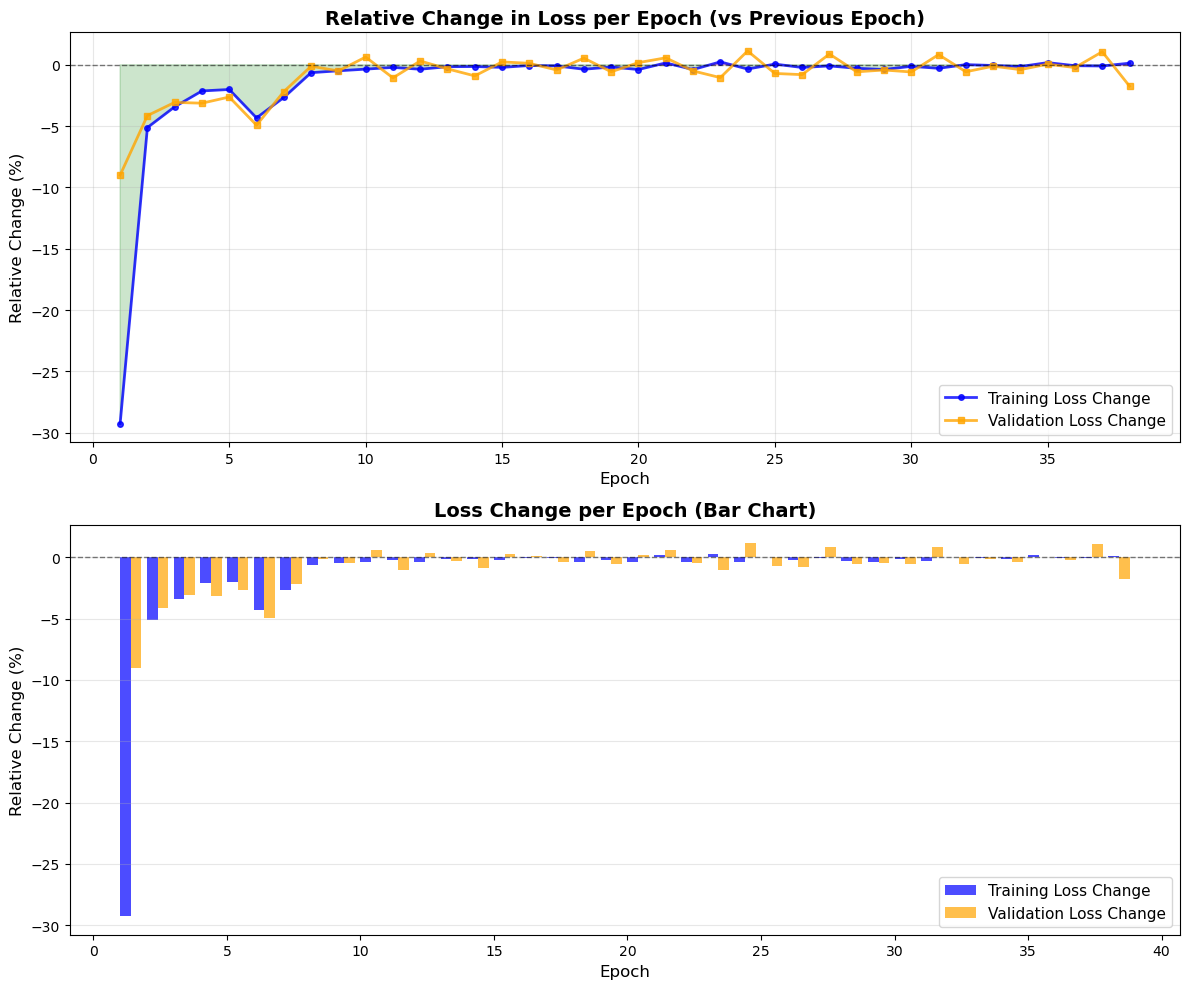

RELATIVE CHANGE STATISTICS

Training Loss:
  Mean change: -1.42%
  Median change: -0.21%


IndexError: single positional indexer is out-of-bounds

In [47]:
# Calculate relative change (percentage) from previous epoch
train_relative_change = train_loss_epoch['train_loss_epoch'].pct_change() * 100
val_relative_change = val_loss_epoch['val_loss_epoch'].pct_change() * 100

# Create dataframes for plotting (skip first epoch since it has no previous value)
train_change_df = pd.DataFrame({
    'epoch': train_loss_epoch['epoch'].iloc[1:],
    'change': train_relative_change.iloc[1:]
})
val_change_df = pd.DataFrame({
    'epoch': val_loss_epoch['epoch'].iloc[1:],
    'change': val_relative_change.iloc[1:]
})

# Create the plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Plot 1: Relative change
ax1.plot(train_change_df['epoch'], train_change_df['change'], 
         label='Training Loss Change', linewidth=2, marker='o', markersize=4, alpha=0.8, color='blue')
ax1.plot(val_change_df['epoch'], val_change_df['change'], 
         label='Validation Loss Change', linewidth=2, marker='s', markersize=4, alpha=0.8, color='orange')
ax1.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Relative Change (%)', fontsize=12)
ax1.set_title('Relative Change in Loss per Epoch (vs Previous Epoch)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Add color fill for positive/negative changes
ax1.fill_between(train_change_df['epoch'], 0, train_change_df['change'], 
                  where=(train_change_df['change'] > 0), alpha=0.2, color='red', interpolate=True)
ax1.fill_between(train_change_df['epoch'], 0, train_change_df['change'], 
                  where=(train_change_df['change'] <= 0), alpha=0.2, color='green', interpolate=True)

# Plot 2: Bar chart showing improvement vs degradation
ax2.bar(train_change_df['epoch'], train_change_df['change'], 
        label='Training Loss Change', alpha=0.7, color='blue', width=0.4, align='edge')
ax2.bar(val_change_df['epoch'] + 0.4, val_change_df['change'], 
        label='Validation Loss Change', alpha=0.7, color='orange', width=0.4, align='edge')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Relative Change (%)', fontsize=12)
ax2.set_title('Loss Change per Epoch (Bar Chart)', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Statistics
print("=" * 60)
print("RELATIVE CHANGE STATISTICS")
print("=" * 60)
print(f"\nTraining Loss:")
print(f"  Mean change: {train_relative_change.iloc[1:].mean():.2f}%")
print(f"  Median change: {train_relative_change.iloc[1:].median():.2f}%")
print(f"  Min change: {train_relative_change.iloc[1:].min():.2f}% (epoch {train_loss_epoch['epoch'].iloc[train_relative_change.iloc[1:].idxmin()]:.0f})")
print(f"  Max change: {train_relative_change.iloc[1:].max():.2f}% (epoch {train_loss_epoch['epoch'].iloc[train_relative_change.iloc[1:].idxmax()]:.0f})")
print(f"  Epochs with improvement: {(train_relative_change.iloc[1:] < 0).sum()}")
print(f"  Epochs with degradation: {(train_relative_change.iloc[1:] > 0).sum()}")

print(f"\nValidation Loss:")
print(f"  Mean change: {val_relative_change.iloc[1:].mean():.2f}%")
print(f"  Median change: {val_relative_change.iloc[1:].median():.2f}%")
print(f"  Min change: {val_relative_change.iloc[1:].min():.2f}% (epoch {val_loss_epoch['epoch'].iloc[val_relative_change.iloc[1:].idxmin()]:.0f})")
print(f"  Max change: {val_relative_change.iloc[1:].max():.2f}% (epoch {val_loss_epoch['epoch'].iloc[val_relative_change.iloc[1:].idxmax()]:.0f})")
print(f"  Epochs with improvement: {(val_relative_change.iloc[1:] < 0).sum()}")
print(f"  Epochs with degradation: {(val_relative_change.iloc[1:] > 0).sum()}")
print("=" * 60)